Dataset shape: (4998, 140)
Normal training data: (2919, 140)
Epoch 1/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0138 - val_loss: 0.0047
Epoch 2/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0047 - val_loss: 0.0043
Epoch 3/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0044 - val_loss: 0.0039
Epoch 4/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0036 - val_loss: 0.0030
Epoch 5/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0030 - val_loss: 0.0027
Epoch 6/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0028 - val_loss: 0.0026
Epoch 7/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0025 - val_loss: 0.0022
Epoch 8/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0021 - val_loss: 0.0019
Epoch 9/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0018 - val_loss: 0.0017
Epoch 10/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0016 - val_loss: 0.0016
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Threshold: 0.003830129976981489
Detection Accuracy: 96.23

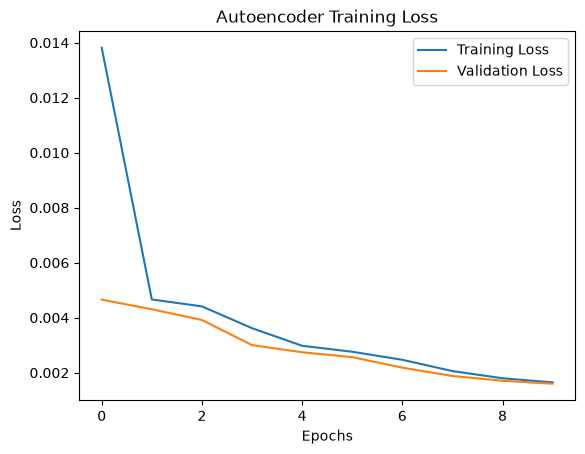

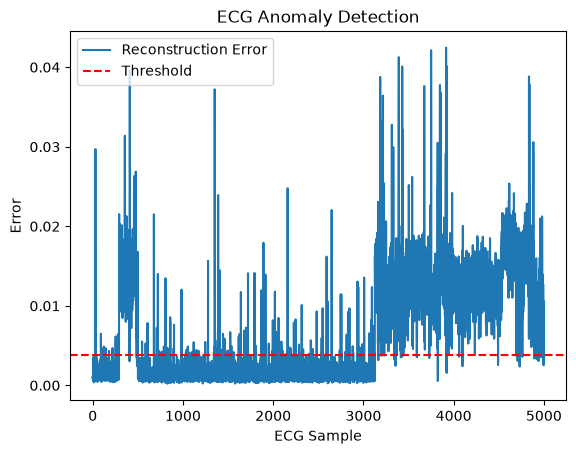

Model saved successfully!


In [1]:

# 1. Import libraries
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

# 2. Load ECG dataset
data = pd.read_csv("ecg.csv", header=None)

# 3. Separate ECG signals and labels
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

print("Dataset shape:", X.shape)

# 4. Normalize ECG signals
scaler = MinMaxScaler()

X = scaler.fit_transform(X)

# 5. Select only normal ECG signals for training
X_train = X[y == 1]

print("Normal training data:", X_train.shape)

# 6. Build Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X.shape[1],)),

    tf.keras.layers.Dense(32, activation="relu"),

    tf.keras.layers.Dense(16, activation="relu"),

    tf.keras.layers.Dense(32, activation="relu"),

    tf.keras.layers.Dense(X.shape[1], activation="sigmoid")
])

# 7. Compile model
model.compile(
    optimizer="adam",
    loss="mse"
)

# 8. Train using normal ECG signals
history = model.fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

# 9. Reconstruct ECG signals
reconstructed = model.predict(X)

# 10. Calculate reconstruction error
errors = np.mean(
    np.square(X - reconstructed),
    axis=1
)

# 11. Set threshold
threshold = np.percentile(errors[y == 1], 95)

print("Threshold:", threshold)

# 12. Detect abnormal ECG signals
predictions = (errors > threshold).astype(int)

# Actual labels: normal = 0, abnormal = 1
actual = (y != 1).astype(int)

# 13. Calculate accuracy
accuracy = np.mean(predictions == actual)

print("Detection Accuracy:", accuracy * 100, "%")

# 14. Plot training loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# 15. Plot reconstruction errors
plt.plot(errors, label="Reconstruction Error")

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.title("ECG Anomaly Detection")
plt.xlabel("ECG Sample")
plt.ylabel("Error")
plt.legend()
plt.show()

# 16. Save model
model.save("ecg_autoencoder.keras")

print("Model saved successfully!")


## Practical 3E – Network Intrusion Detection using Autoencoder (NSL-KDD Dataset)

Problem statement: Use an Autoencoder to implement Network Intrusion Detection on the NSL-KDD dataset. Train the Autoencoder using normal network traffic and identify attacks using reconstruction error.

[Aman Gautam — Developer Portfolio](https://images.openai.com/static-rsc-4/CHONlnZ7J2kjCOYtQToEqMIg_4LfJ66uteUVqfMKA_ioMaNuKC4vxLl-dDJDOGCrIOvd0-kZxqBXPS2i_AV-3srZw-I4CXoh684vdKL6uvkcqTCZBw3hkCZ-bJtxTWV8wgaN3omugPwNtfXA8dBy8M_llAVPVBrg4JSUBCLLiy8?purpose=inline)

[aman9673.github.io](https://aman9673.github.io/?utm_source=chatgpt.com)

### 1. First, understand the practical

Imagine a computer network where thousands of requests are happening.

- Normal traffic: regular user login, browsing, file downloads.
- Attack traffic: unauthorized access, suspicious requests, denial-of-service attacks.

The Autoencoder learns the behaviour of normal network traffic. When it receives unusual traffic, reconstruction error becomes high.

NSL-KDD Dataset

Network traffic records

Preprocessing

Categorical encoding + normalization

Autoencoder

Encoder → Decoder

Reconstruction Error

Intrusion Detection

High error = Attack

### 2. Important correction in your code

Your code currently uses ECG data, not NSL-KDD

You have copied the ECG practical code. The Autoencoder concept is similar, but the dataset and preprocessing are different.

| ECG practical           | NSL-KDD practical                |
| ----------------------- | -------------------------------- |
| `ecg.csv`               | NSL-KDD train/test files         |
| ECG signals             | Network traffic records          |
| Numerical signal values | Numerical + categorical features |
| No categorical encoding | One-hot encoding required        |
| ECG anomaly detection   | Network intrusion detection      |

For NSL-KDD, categorical features such as `protocol_type`, `service`, and `flag` must be converted into numerical values before training.

### 3. Understand the code you shared

Your current code still demonstrates the general Autoencoder workflow.

Step 1 – Import libraries

```
import pandas as pdimport numpy as npimport tensorflow as tfimport matplotlib.pyplot as pltfrom sklearn.preprocessing import MinMaxScaler
```

- Pandas: handles the dataset.
- NumPy: mathematical operations.
- TensorFlow: builds the Autoencoder.
- Matplotlib: displays graphs.
- MinMaxScaler: scales numerical values between 0 and 1.

Step 2 – Load dataset

```
data = pd.read_csv("ecg.csv", header=None)
```

For the actual practical, this must load NSL-KDD data instead.

Step 3 – Separate features and labels

```
X = data.iloc[:, :-1].valuesy = data.iloc[:, -1].values
```

- `X` contains input features.
- `y` contains normal/attack labels.

Step 4 – Normalize data

```
scaler = MinMaxScaler()X = scaler.fit_transform(X)
```

Scales numerical features to the range 0–1.

For NSL-KDD, categorical columns must first be encoded using techniques such as One-Hot Encoding.

Step 5 – Select normal data

```
X_train = X[y == 1]
```

Selects only normal records for training in your ECG example.

For NSL-KDD, you must select records whose label is `normal`.

Step 6 – Build Autoencoder

```
model = tf.keras.Sequential([    tf.keras.layers.Input(shape=(X.shape[1],)),    tf.keras.layers.Dense(32, activation="relu"),    tf.keras.layers.Dense(16, activation="relu"),    tf.keras.layers.Dense(32, activation="relu"),    tf.keras.layers.Dense(X.shape[1], activation="sigmoid")])
```

| Layer     | Purpose                         |
| --------- | ------------------------------- |
| Input     | Receives network features       |
| Dense(32) | Learns patterns                 |
| Dense(16) | Compresses information          |
| Dense(32) | Reconstructs information        |
| Output    | Produces reconstructed features |

This is a basic fully connected Autoencoder.

Step 7 – Compile model

```
model.compile(    optimizer="adam",    loss="mse")
```

- Adam: optimizer.
- MSE: calculates reconstruction error.

Step 8 – Train model

```
history = model.fit(    X_train,    X_train,    epochs=10,    batch_size=32,    validation_split=0.2)
```

The model receives the same data as input and output because it learns to reconstruct normal traffic.

Step 9 – Calculate reconstruction error

```
reconstructed = model.predict(X)errors = np.mean(    np.square(X - reconstructed),    axis=1)
```

Calculates the difference between original and reconstructed network traffic.

Step 10 – Set threshold

```
threshold = np.percentile(errors[y == 1], 95)
```

In your ECG example, this calculates the 95th percentile of normal-sample errors.

For NSL-KDD, calculate it using normal training/validation records.

Step 11 – Detect intrusions

```
predictions = (errors > threshold).astype(int)
```

- `0` = Normal traffic.
- `1` = Attack traffic.

Step 12 – Evaluate and save

```
accuracy = np.mean(predictions == actual)
```

Calculates the percentage of correct predictions.

```
model.save("ecg_autoencoder.keras")
```

Saves the trained model. For the actual practical, use a filename such as `nsl_kdd_autoencoder.keras`.

### 4. Important viva questions

Q1. What is NSL-KDD?

It is a network intrusion detection dataset containing normal and malicious network traffic records.

Q2. What is network intrusion detection?

It is the process of identifying unauthorized or suspicious activities in a computer network.

Q3. Why do we use an Autoencoder?

It learns normal network traffic patterns and identifies unusual traffic using reconstruction error.

Q4. What is categorical encoding?

It converts text-based values into numerical representations that a machine-learning model can understand.

Q5. What is One-Hot Encoding?

It converts categories into separate binary columns.

Q6. Why train only on normal traffic?

So the model learns normal network behaviour and can identify unusual traffic.

Q7. What is reconstruction error?

The difference between original network traffic features and reconstructed features.

Q8. What is a threshold?

A boundary used to classify network traffic as normal or an attack.

Q9. What is the difference between supervised and unsupervised learning?

Supervised learning uses labelled data for training. Anomaly detection with an Autoencoder can learn normal patterns without using attack labels during training.

Q10. What is the role of MSE?

It measures the squared difference between original and reconstructed data.

### 5. What to tell the examiner

"I implemented network intrusion detection using an Autoencoder on the NSL-KDD dataset. First, I preprocessed the network traffic by encoding categorical features and scaling numerical features. Then I selected only normal traffic for training. I built an Autoencoder with an encoder and decoder to learn normal network patterns. Finally, I calculated reconstruction errors and used a threshold to identify suspicious network traffic as attacks."

### 6. Quick revision

| Parameter      | Value                    |
| -------------- | ------------------------ |
| Dataset        | NSL-KDD                  |
| Model          | Autoencoder              |
| Input          | Network traffic features |
| Preprocessing  | Encoding + scaling       |
| Training data  | Normal traffic           |
| Encoder layers | 32 → 16                  |
| Decoder layers | 32 → Input size          |
| Optimizer      | Adam                     |
| Loss           | MSE                      |
| Epochs         | 10                       |
| Detection      | Reconstruction error     |

### One important thing before running the practical

Your current code is not ready for NSL-KDD because it loads `ecg.csv` and expects numerical ECG labels.

NSL-KDD commonly comes in files such as `KDDTrain+.txt` and `KDDTest+.txt`, with categorical columns and attack-name labels. The preprocessing must handle those correctly, and the train/test feature columns must match.

Share your NSL-KDD dataset file or tell me its filename and format. I'll convert this into complete, beginner-friendly runnable code for Practical 3E using your local dataset.